# Predicting joint contact forces from gait inputs

Subjects: ACL-injured participants from an asymmetric walking study.

Joint contact forces are the resultant forces transmitted across a joint and reflect the combined effects of external loading and muscle forces. They are important determinants of the mechanical loading experienced by articular cartilage. Individuals who have undergone anterior cruciate ligament (ACL) reconstruction often exhibit altered knee joint loading during walking, which may contribute to their increased risk of post-traumatic knee osteoarthritis. Quantifying joint contact forces is therefore important for understanding changes in joint loading, monitoring rehabilitation, and evaluating interventions designed to improve walking mechanics.

Direct measurement of joint contact forces *in vivo* generally requires instrumented joint implants, which are not routinely available in clinical practice. Instead, these forces are estimated using musculoskeletal models implemented in software such as OpenSim. The process begins with gait laboratory measurements, including the positions of reflective markers attached to the body and ground reaction forces recorded during walking. A generic musculoskeletal model is scaled to the participant's anatomy, joint angles are estimated from marker trajectories, and muscle forces are estimated using the joint kinematics and external forces. These quantities are then used to calculate the resultant forces transmitted across the joints. Although widely used in biomechanics research, this computational pipeline can require hours to process walking data from multiple participants, limiting its potential for routine clinical use.

The goal of this project is to develop a Gaussian process (GP) emulator that predicts joint contact forces without repeating the computationally expensive OpenSim analysis. An emulator is a statistical model trained to approximate the outputs of a computational model. Here, OpenSim provides the training data by computing joint contact forces for a collection of recorded strides. The GP then learns the relationship between the measured gait characteristics and the corresponding OpenSim force estimates. Specifically, the inputs consist of three ground reaction force curves, five joint angle curves, treadmill belt speed, body mass, and height, while the outputs are the joint contact force curves at the hip, knee, and ankle. Because both the gait measurements and joint contact forces vary throughout the gait cycle, the emulator must learn a nonlinear relationship between multiple input curves and multiple output curves. A GP provides a flexible framework for modeling these relationships while accounting for dependence across gait time and quantifying uncertainty in its predictions. Once fitted, the emulator can estimate the joint contact force curves of a new stride without running OpenSim, potentially reducing computation from hours to seconds or less. With sufficient predictive accuracy and computational speed, this approach could enable joint loading assessments during clinical gait evaluations and support more timely adjustments to rehabilitation strategies following ACL reconstruction.

The data used to develop and evaluate the emulator consist of 620 right-leg strides collected from fifteen participants who had undergone ACL reconstruction. Each participant walked on an instrumented treadmill at belt speeds of 1.0, 1.25, and 1.5 m/s. For each stride, the input measurements were recorded and the corresponding joint contact forces were estimated using OpenSim. All input and output curves were normalized to 101 equally spaced points over the gait cycle, defined from one heel strike to the next. The data were divided by participant, with twelve participants assigned to training and three held out for testing. This participant-level split ensures that no strides from the test participants are used during model fitting, allowing predictive performance to be evaluated on individuals not represented in the training data. This evaluation is particularly important for assessing whether the emulator can generalize across individuals, a necessary condition for its eventual application to new patients.

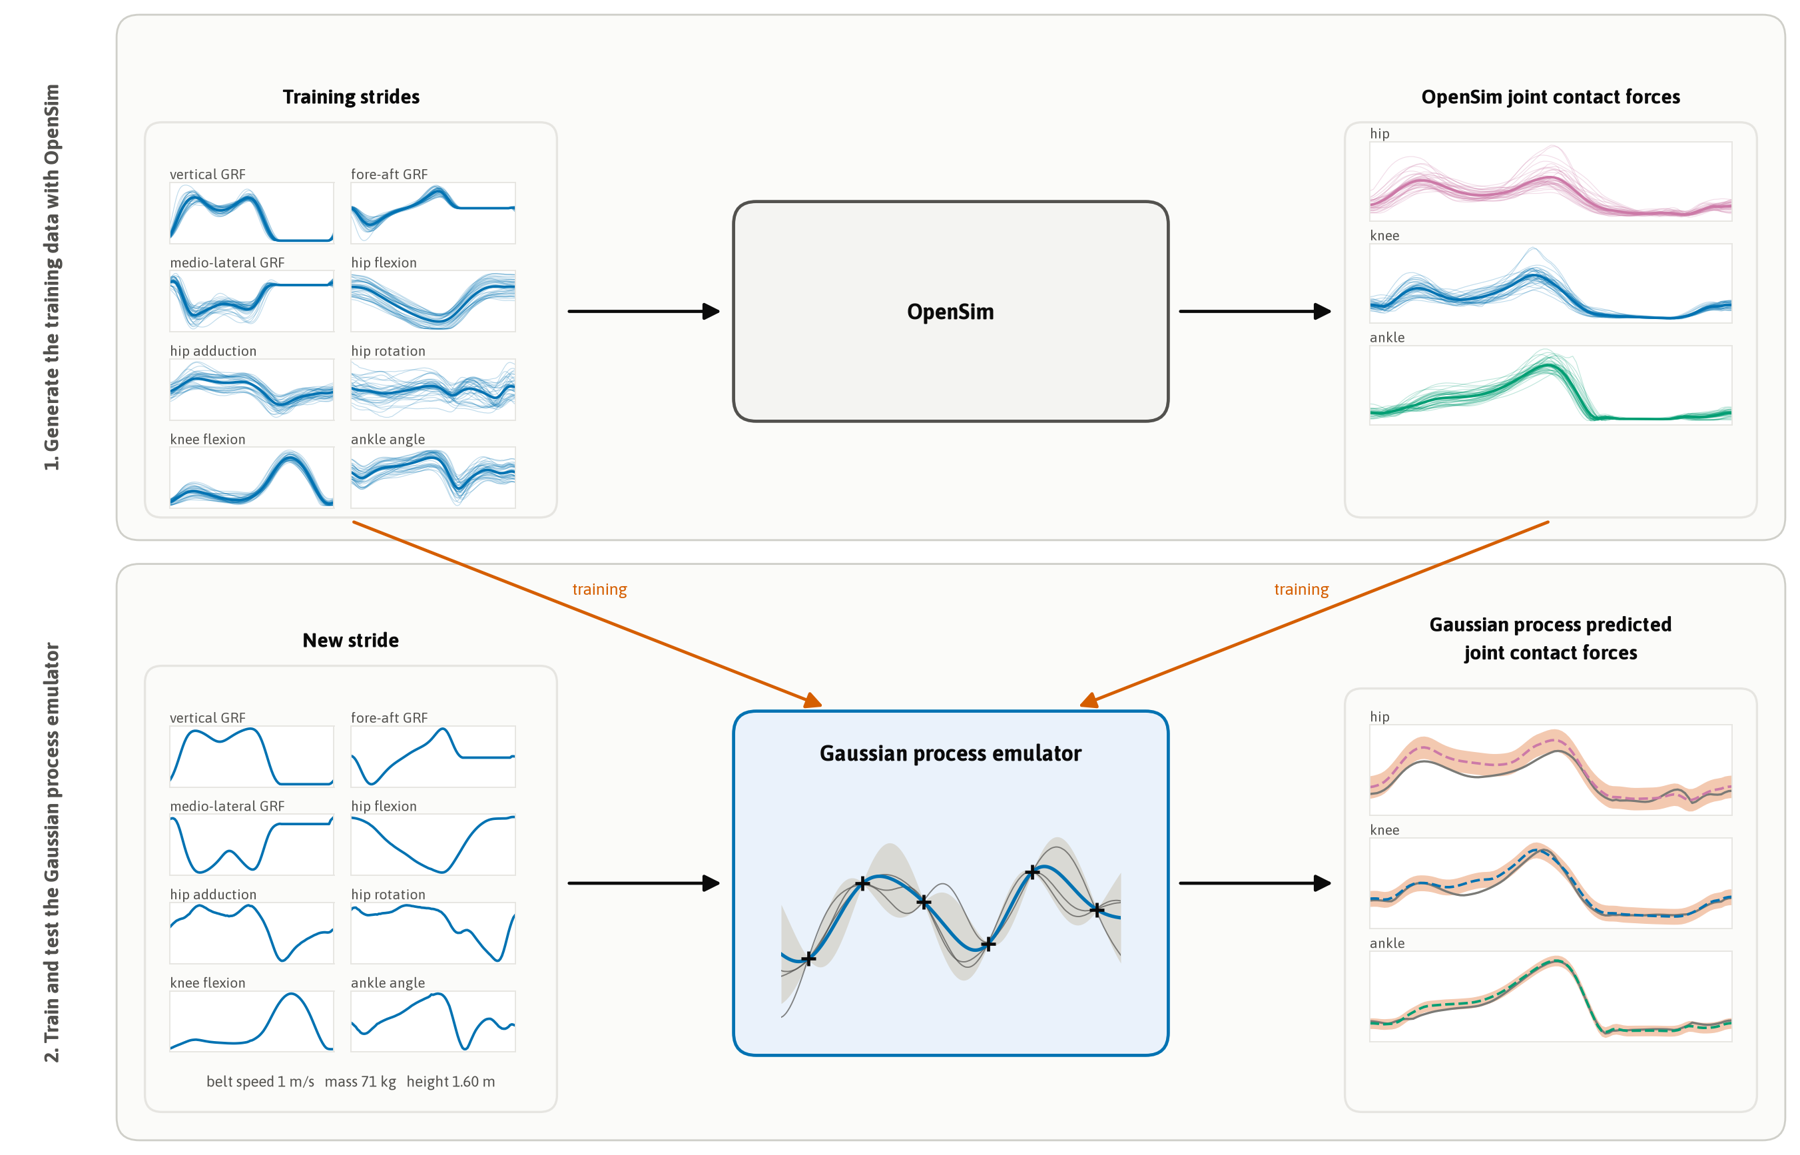


## Setup

Load the necessary libraries.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SPEED_COLOURS = {1.0: "#0072B2", 1.25: "#D55E00", 1.4: "#000000", 1.5: "#009E73"}
JOINT_COLOURS = {"hip": "#CC79A7", "knee": "#0072B2", "ankle": "#009E73"}

## Data

One row is one stride of the right leg. `x-*.csv` holds the inputs (three ground reaction force curves, five joint angle curves, belt speed, mass, height), `y-*.csv` the outputs (the hip, knee and ankle joint contact force curves from OpenSim). Each curve is sampled at 101 points of the gait cycle, 0 to 100 %, heel strike to heel strike. Row i of x and row i of y are the same stride.

In [ ]:
!gdown --folder "https://drive.google.com/drive/folders/1CI5OAxzB9qYI9vIxW1f0cGE4SN1hhyBj" -q

In [ ]:
print(open("data/log.txt").read())

In [ ]:
x_train = pd.read_csv("data/x-train.csv")
y_train = pd.read_csv("data/y-train.csv")
x_test = pd.read_csv("data/x-test.csv")
y_test = pd.read_csv("data/y-test.csv")

## Explore

A data frame with one row per stride: three identifier columns, three scalar inputs, then the curves, one column per gait point.

In [ ]:
x_train.shape, y_train.shape, x_test.shape, y_test.shape

In [ ]:
x_train.columns[:12].tolist()

In [ ]:
x_train.iloc[:5, :10]

In [ ]:
y_train.columns[:8].tolist()

In [ ]:
x_train["subject"].value_counts().sort_index()

In [ ]:
x_test["subject"].value_counts().sort_index()

In [ ]:
x_train["belt_speed_mps"].value_counts().sort_index()

In [ ]:
x_train.groupby("subject")[["mass_kg", "height_m"]].first()

## Visualize the inputs

A curve called `name` occupies the 101 columns `name_t000` to `name_t100`; `curve` returns it as a `(strides, 101)` array. Every stride of each input curve is shown, colored by belt speed, with the mean curve of each speed on top. Stance is roughly the first 62 % of the cycle (dotted line), swing the rest.

In [ ]:
GRID = np.arange(101)

INPUT_CURVES = ["grf_vertical_BW", "grf_anteroposterior_BW", "grf_mediolateral_BW",
                "hip_flexion_deg", "hip_adduction_deg", "hip_rotation_deg", "knee_flexion_deg", "ankle_angle_deg"]
OUTPUT_CURVES = ["hip_jcf_BW", "knee_jcf_BW", "ankle_jcf_BW"]

def curve(df, name):
    return df[[f"{name}_t{t:03d}" for t in GRID]].to_numpy()

In [ ]:
def overlay(ax, df, name):
    C = curve(df, name)
    speeds = df["belt_speed_mps"].to_numpy()
    for v in sorted(SPEED_COLOURS):
        rows = speeds == v
        if rows.any():
            ax.plot(GRID, C[rows].T, color=SPEED_COLOURS[v], lw=0.5, alpha=0.25)
    for v in sorted(SPEED_COLOURS):
        rows = speeds == v
        if rows.any():
            ax.plot(GRID, C[rows].mean(axis=0), color=SPEED_COLOURS[v], lw=2.5, label=f"{v:g} m/s (n={rows.sum()})")
    ax.axvline(62, color="grey", lw=0.8, ls=":")
    ax.set_title(name, loc="left"); ax.set_xlim(0, 100); ax.grid(alpha=0.3)

### Training inputs

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, name in zip(axes.flat, INPUT_CURVES):
    overlay(ax, x_train, name)
axes[0][0].legend(frameon=False, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Gait cycle [%]")
fig.tight_layout()

### Testing inputs

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, name in zip(axes.flat, INPUT_CURVES):
    overlay(ax, x_test, name)
axes[0][0].legend(frameon=False, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Gait cycle [%]")
fig.tight_layout()

## Visualize the outputs

The joint contact force is the total force pressing the two bones of a joint together: the external load plus the compression produced by the muscles that cross the joint.

### Training outputs

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, OUTPUT_CURVES):
    overlay(ax, y_train, name)
    ax.set_xlabel("Gait cycle [%]")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()

### Testing outputs

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, OUTPUT_CURVES):
    overlay(ax, y_test, name)
    ax.set_xlabel("Gait cycle [%]")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()

## Gaussian process emulator

Let $i = 1, \dots, n$ index the training strides, with $n = 480$, and let $t \in \{0, 1, \dots, 100\}$ denote the percent of the gait cycle. For stride $i$ the input is the vector $\mathbf{x}_i$ that collects the eight input curves evaluated at the 101 gait points together with the three scalars, so that $\mathbf{x}_i \in \mathbb{R}^{811}$. The output is one joint contact force curve, $y_i(t)$, and a separate emulator is fitted for the hip, the knee and the ankle. The $n \times 101$ matrix $\mathbf{Y}$ holds $y_i(t)$ in row $i$ and column $t$.

The emulator models the output as a population mean curve plus a stride-specific deviation that depends on the inputs,
$$
y_i(t) = m(t) + f(\mathbf{x}_i, t) + \varepsilon_i(t), \qquad \varepsilon_i(t) \sim \mathcal{N}(0, \sigma_\varepsilon^2),
$$
where $m(t)$ is the mean of the training curves at gait point $t$, $f$ is a Gaussian process and $\varepsilon_i(t)$ is independent noise with variance $\sigma_\varepsilon^2$, the nugget effect. A Gaussian process is a distribution over functions such that the values of $f$ at any finite set of points are jointly Gaussian. It is specified by a mean function, taken to be zero here because $m(t)$ has been removed, and by a covariance function, that gives the covariance between the values of $f$ at two points,
$$
f \sim \mathcal{GP}\big(0, C\big), \qquad \operatorname{Cov}\!\big(f(\mathbf{x}, t), f(\mathbf{x}', t')\big) = C\big((\mathbf{x}, t), (\mathbf{x}', t')\big).
$$

The covariance function is separable in the inputs and in gait time,
$$
C\big((\mathbf{x}, t), (\mathbf{x}', t')\big) = \sigma_f^2 \, C_x(\mathbf{x}, \mathbf{x}') \, C_t(t, t'),
$$
where $\sigma_f^2$ is the variance, $C_x$ describes how similar two strides are as a function of their inputs and $C_t$ describes how strongly two gait points are correlated. Both are Matérn covariance functions with smoothness $5/2$, which is the standard choice for functions that are smooth but not infinitely so,
$$
C_x(\mathbf{x}, \mathbf{x}') = \Big(1 + \sqrt{5}\, r + \tfrac{5}{3} r^2\Big) e^{-\sqrt{5}\, r}, \qquad C_t(t, t') = \Big(1 + \sqrt{5}\, \tau + \tfrac{5}{3} \tau^2\Big) e^{-\sqrt{5}\, \tau}, \quad \tau = \frac{|t - t'|}{\ell_t}.
$$
The distance $r$ between two strides is the root mean squared difference of their $p = 811$ standardized coordinates divided by a single range $\ell$,
$$
r^2 = \frac{1}{p\, \ell^2} \sum_{j=1}^{p} \big(x_j - x'_j\big)^2,
$$
after each coordinate has been standardized on the training strides. The two ranges are the range parameters of the Matérn covariance functions, and they have the same reading in both coordinates. The input range $\ell$ is the root mean squared difference in standardized inputs at which the correlation between the deviations of two strides has fallen to $0.52$, and beyond about $2.7\,\ell$ it is below $0.05$. A small input range means that the force changes quickly as the inputs change, so two strides have to be close in their inputs for their forces to be alike. The temporal range $\ell_t$ is the same quantity for two gait points, in percent of the gait cycle, and it sets how far along the cycle two values of the force remain correlated.

The parameters are $\boldsymbol{\theta} = (\ell, \sigma_f^2, \ell_t, \sigma_\varepsilon^2)$. They are chosen by maximizing the log likelihood of the training curves,
$$
\log p(\mathbf{Y} \mid \boldsymbol{\theta}) = -\tfrac{1}{2}\, \mathbf{y}^\top \boldsymbol{\Sigma}^{-1} \mathbf{y} - \tfrac{1}{2} \log \det \boldsymbol{\Sigma} - \tfrac{N}{2} \log 2\pi,
$$
where $\mathbf{y} = \operatorname{vec}(\mathbf{Y} - \mathbf{1}\, \mathbf{m}^\top)$ stacks the centered curves, $N = 101\, n$, and $\boldsymbol{\Sigma} = \sigma_f^2\, \boldsymbol{\Sigma}_x \otimes \boldsymbol{\Sigma}_t + \sigma_\varepsilon^2 \mathbf{I}$ with $\boldsymbol{\Sigma}_x$ the $n \times n$ matrix of $C_x$ between training strides and $\boldsymbol{\Sigma}_t$ the $101 \times 101$ matrix of $C_t$ between gait points. The Kronecker structure means that $\boldsymbol{\Sigma}$, which has $N = 48{,}480$ rows, never has to be formed: its inverse and determinant follow from the eigendecompositions of $\boldsymbol{\Sigma}_x$ and $\boldsymbol{\Sigma}_t$ alone.

For a new stride with inputs $\mathbf{x}_*$ the emulator returns the predictive distribution of its joint contact force curve, which is Gaussian with mean and variance
$$
\mathbb{E}\big[y_*(t)\big] = m(t) + \mathbf{c}_*^\top \boldsymbol{\Sigma}^{-1} \mathbf{y}, \qquad \operatorname{Var}\big[y_*(t)\big] = \sigma_f^2 - \mathbf{c}_*^\top \boldsymbol{\Sigma}^{-1} \mathbf{c}_* + \sigma_\varepsilon^2,
$$
where $\mathbf{c}_*$ is the vector of covariances between $(\mathbf{x}_*, t)$ and the training points. The mean curve $m(t)$ in this formula is the one estimated from the training strides; the only quantity of the new stride that enters the prediction is its inputs $\mathbf{x}_*$, and its joint contact force is used afterwards, only to score the prediction. The mean is the prediction and the standard deviation gives the 95 % prediction interval as the mean plus and minus $1.96$ standard deviations.

The emulator is evaluated on the strides of the three held-out participants. For point accuracy the root mean squared error between the predicted and the OpenSim curves is reported over all gait points. For the predictive distribution the coverage of the 95 % interval, the fraction of OpenSim values that fall inside it, is compared with its nominal 95 %, and the continuous ranked probability score summarizes accuracy and calibration in one number in body weights.

### Mean curve and residuals

The mean curve $m(t)$ of each joint is the average of the training curves at every gait point. The Gaussian process models what remains after it is removed, the residual $y_i(t) - m(t)$ of each stride.

In [ ]:
Y_train = {name: curve(y_train, name) for name in OUTPUT_CURVES}
m_t = {name: Y_train[name].mean(axis=0) for name in OUTPUT_CURVES}
R_train = {name: Y_train[name] - m_t[name] for name in OUTPUT_CURVES}

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
speeds = x_train["belt_speed_mps"].to_numpy()
for j, name in enumerate(OUTPUT_CURVES):
    ax = axes[0][j]
    for v in sorted(SPEED_COLOURS):
        rows = speeds == v
        if rows.any():
            ax.plot(GRID, Y_train[name][rows].T, color=SPEED_COLOURS[v], lw=0.5, alpha=0.2)
    ax.plot(GRID, m_t[name], color="#0b0b0b", lw=2.5, label="mean curve m(t)")
    ax.set_title(name, loc="left"); ax.grid(alpha=0.3)
    ax = axes[1][j]
    for v in sorted(SPEED_COLOURS):
        rows = speeds == v
        if rows.any():
            ax.plot(GRID, R_train[name][rows].T, color=SPEED_COLOURS[v], lw=0.5, alpha=0.3)
    ax.axhline(0, color="#0b0b0b", lw=1.5)
    ax.set_title(name + ", residual", loc="left"); ax.grid(alpha=0.3); ax.set_xlabel("Gait cycle [%]")
axes[0][0].legend(frameon=False, fontsize=9); axes[0][0].set_ylabel("JCF [BW]"); axes[1][0].set_ylabel("JCF - m(t) [BW]")
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=SPEED_COLOURS[v], lw=2.5, label=f"{v:g} m/s") for v in sorted(SPEED_COLOURS) if (speeds == v).any()]
axes[1][0].legend(handles=handles, frameon=False, fontsize=9)
fig.tight_layout()

### Inputs as a feature vector

Each stride becomes the vector $\mathbf{x}_i$ of its eight curves and three scalars. Every curve is standardized with its training mean curve and one training standard deviation, and every scalar with its training mean and standard deviation, so that all 811 coordinates are on a comparable scale and one range can serve them all.

In [ ]:
def build_features(x, x_ref):
    cols = []
    for name in INPUT_CURVES:
        C, C_ref = curve(x, name), curve(x_ref, name)
        cols.extend(((C - C_ref.mean(axis=0)) / C_ref.std()).T)
    for name in ["belt_speed_mps", "mass_kg", "height_m"]:
        cols.append((x[name].to_numpy() - x_ref[name].mean()) / x_ref[name].std())
    return np.array(cols).T

F_train = build_features(x_train, x_train)
F_test = build_features(x_test, x_train)
F_train.shape, F_test.shape


### Covariance function

The Matérn 5/2 covariance function on the grouped distance between strides and on the distance between gait points.

In [ ]:
def matern52(r):
    s = np.sqrt(5.0) * r
    return (1.0 + s + s**2 / 3.0) * np.exp(-s)

def sqdist(A, B, l):
    d = (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T      # squared Euclidean distance between rows
    return np.maximum(d, 0.0) / (A.shape[1] * l**2)                         # mean over coordinates, divided by the range squared


### Likelihood

The negative log likelihood of the centred training curves, computed through the eigendecompositions of $\boldsymbol{\Sigma}_x$ and $\boldsymbol{\Sigma}_t$. The parameters are kept on the log scale so that the optimizer can move freely.

In [ ]:
class SpaceTimeGP:
    def __init__(self, X, R, t):
        self.X, self.R, self.t = X, R, t          # X (n, p) features, R (n, T) residuals y_i(t) - m(t)
        self.n, self.T = R.shape

    def unpack(self, theta):
        return np.exp(theta)                      # l, sf2, lt, sn2

    def eig(self, theta):
        l, sf2, lt, sn2 = self.unpack(theta)
        Kx = sf2 * matern52(np.sqrt(sqdist(self.X, self.X, l)))
        Kt = matern52(np.abs(self.t[:, None] - self.t[None, :]) / lt)
        lam, U = np.linalg.eigh(Kx + 1e-8 * np.eye(self.n))
        mu, V = np.linalg.eigh(Kt + 1e-8 * np.eye(self.T))
        return U, V, lam[:, None] * mu[None, :] + sn2

    def nlml(self, theta):
        U, V, D = self.eig(theta)
        Rt = U.T @ self.R @ V
        return 0.5 * np.sum(Rt**2 / D) + 0.5 * np.sum(np.log(D)) + 0.5 * self.n * self.T * np.log(2 * np.pi)


### Maximum Likelihood Estimation

One emulator per joint. The optimizer starts from an input range of 2, a variance of 1, a temporal range of 10 % of the gait cycle and a nugget effect of 0.01, and stops when the likelihood no longer improves. Each fit takes well under a minute. The table lists, per joint, the input range in standardized units, the variance and the nugget effect in body weights squared, the temporal range in percent of the gait cycle, and the negative log likelihood at the maximum.

In [ ]:
from scipy.optimize import minimize
import time

def fit(gp, theta0, maxiter=150):
    state = {"iteration": 0, "t0": time.time()}
    def report(theta):
        state["iteration"] += 1
        if state["iteration"] % 10 == 0:
            l, sf2, lt, sn2 = gp.unpack(theta)
            print(f"  iteration {state['iteration']:3d}  negative log likelihood {gp.nlml(theta):12.1f}  input range {l:.3f}  variance {sf2:.3f}  "
                  f"temporal range {lt:.2f} %  nugget effect {sn2:.1e}  [{time.time() - state['t0']:.0f} s]", flush=True)
    return minimize(gp.nlml, theta0, method="L-BFGS-B", options={"maxiter": maxiter, "eps": 1e-3}, callback=report)

models, fitted = {}, []
for name in OUTPUT_CURVES:
    print(name)
    t0 = time.time()
    s = Y_train[name].std()
    gp = SpaceTimeGP(F_train, R_train[name] / s, GRID.astype(float))   # residuals scaled to unit variance
    theta0 = np.log([2.0, 1.0, 10.0, 0.01])
    res = fit(gp, theta0)
    gp.theta, gp.scale, gp.nlml_value = res.x, s, res.fun
    models[name] = gp
    l, sf2, lt, sn2 = gp.unpack(res.x)
    fitted.append(pd.Series({"input range [standardized units]": l, "variance [BW²]": sf2 * s**2, "temporal range [% gait cycle]": lt, "nugget effect [BW²]": sn2 * s**2,
                             "negative log likelihood": res.fun, "fit time [s]": time.time() - t0}, name=name.split("_")[0]))
    print(f"  {res.message}, {res.nit} iterations, {time.time() - t0:.0f} s")
table = pd.DataFrame(fitted).T
table.columns.name = "joint"
shown = table.apply(lambda col: col.map("{:.3f}".format))
shown.loc["nugget effect [BW²]"] = table.loc["nugget effect [BW²]"].map("{:.2e}".format)
shown

### Prediction

For each test stride the emulator receives its feature vector only. The prediction is the training mean curve $m(t)$ plus the Gaussian process correction, and the predictive standard deviation gives the 95 % interval. The joint contact forces of the test strides are read only in the next section, to score the predictions.

In [ ]:
def predict(gp, F_new):
    l, sf2, lt, sn2 = gp.unpack(gp.theta)
    U, V, D = gp.eig(gp.theta)
    A = U @ ((U.T @ gp.R @ V) / D) @ V.T                                        # Sigma^{-1} applied to the training residuals
    Kxs = sf2 * matern52(np.sqrt(sqdist(F_new, gp.X, l)))                      # (new strides, training strides)
    Kt = matern52(np.abs(gp.t[:, None] - gp.t[None, :]) / lt)
    mean = Kxs @ A @ Kt
    var = sf2 - ((U.T @ Kxs.T)**2).T @ (1.0 / D) @ ((V.T @ Kt)**2) + sn2
    return mean, np.sqrt(np.maximum(var, 1e-12))

pred_mean, pred_sd = {}, {}
for name in OUTPUT_CURVES:
    gp = models[name]
    mean, sd = predict(gp, F_test)
    pred_mean[name] = m_t[name] + gp.scale * mean      # training mean curve plus the scaled correction
    pred_sd[name] = gp.scale * sd
pred_mean["knee_jcf_BW"].shape

### Results

The out-of-sample scores on the 140 strides of the three held-out participants: the root mean squared error over all gait points, the continuous ranked probability score of the Gaussian predictive distribution, and the coverage of the 95 % interval, all in body weights except the coverage.

In [ ]:
from scipy.stats import norm

Y_test = {name: curve(y_test, name) for name in OUTPUT_CURVES}

def crps(y, mu, sd):
    z = (y - mu) / sd
    return np.mean(sd * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi)))

rows = []
for name in OUTPUT_CURVES:
    y, mu, sd = Y_test[name], pred_mean[name], pred_sd[name]
    rows.append(pd.Series({"RMSE [BW]": np.sqrt(np.mean((mu - y)**2)), "CRPS [BW]": crps(y, mu, sd),
                           "95% coverage [%]": np.mean(np.abs(y - mu) <= 1.96 * sd) * 100}, name=name.split("_")[0]))
results = pd.DataFrame(rows).T
results.columns.name = "joint"
results.round(3)

### Predicted curves

One stride per held-out participant, the one with the median error, for each joint: the OpenSim curve, the emulator's prediction and its 95 % interval.

In [ ]:
subjects_test = sorted(x_test["subject"].unique())
fig, axes = plt.subplots(3, 3, figsize=(18, 11), sharex=True)
for j, name in enumerate(OUTPUT_CURVES):
    y, mu, sd = Y_test[name], pred_mean[name], pred_sd[name]
    for c, s in enumerate(subjects_test):
        rows = np.where(x_test["subject"].to_numpy() == s)[0]
        err = np.sqrt(np.mean((mu[rows] - y[rows])**2, axis=1))
        i = rows[np.argsort(err)[len(err) // 2]]
        ax = axes[j][c]
        ax.fill_between(GRID, mu[i] - 1.96 * sd[i], mu[i] + 1.96 * sd[i], color="#f3c9b0", lw=0, label="95% interval")
        ax.plot(GRID, y[i], color="#1f3b5c", lw=2.2, label="OpenSim (Truth)")
        ax.plot(GRID, mu[i], color="#D55E00", lw=2.2, ls="--", label="emulator")
        ax.set_title(f"{name.split('_')[0]}: {s.replace('NIH_ACL_', '')}, {x_test.loc[i, 'block']}, stride {x_test.loc[i, 'stride_in_block']}, {x_test.loc[i, 'belt_speed_mps']:g} m/s", loc="left", fontsize=10)
        ax.text(0.98, 0.97, f"RMSE {err[len(err) // 2]:.2f} BW, {np.mean(np.abs(y[i] - mu[i]) <= 1.96 * sd[i]) * 100:.0f}% inside", transform=ax.transAxes, ha="right", va="top", fontsize=9)
        ax.set_ylim(0, max(y[i].max(), (mu[i] + 1.96 * sd[i]).max()) * 1.3); ax.grid(alpha=0.3)
        if c == 0:
            ax.set_ylabel("JCF [BW]")
        if j == 2:
            ax.set_xlabel("Gait cycle [%]")
axes[0][0].legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()